<center><h1>Zuo_Xiyi_HW5</h1></center>
<br>
<center><font size="4">Decision Trees, the LASSO, and Boosting</font></center>

**Name:** Xiyi Zuo
**GitHub Username:** Kiera111
**USC ID:** 9330953458


### Package imports

All dependencies are imported together so the notebook can be run sequentially from a clean kernel.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LassoCV, LinearRegression, RidgeCV
from sklearn.metrics import accuracy_score, mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from xgboost import XGBRegressor

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 140)
pd.set_option("display.width", 120)
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 552
DATA_DIR = Path("../data")
N_TRAIN = 1495
CV_FOLDS = 5


## 1. Decision Trees as Interpretable Models

The Acute Inflammations data set has two diagnoses for each patient: inflammation of the urinary bladder and nephritis of renal pelvis origin. A patient can have either disease, both, or neither, so the problem is multi-label.

Three ways to grow a tree are available. scikit-learn's `DecisionTreeClassifier` accepts a two-column response and chooses each split from the joint impurity of the two labels. Binary relevance grows one tree per label and ignores dependence while the trees are fit. Label powerset maps each pair of labels to one class (`neither`, `bladder only`, `nephritis only`, `both`) and grows a single multiclass tree.

Label powerset is the right choice for the tree that is plotted and turned into rules. The two diseases are medically dependent: nephritis often occurs together with bladder inflammation, and the expert diagnosis is the joint outcome. A powerset leaf names that outcome directly, so an IF-THEN rule is a diagnosis rather than two separate yes/no answers. Binary relevance can emit a combination the expert rules never produce, because each tree never sees the other label. The native multi-output tree does use both labels when it splits, but a leaf still stores two separate predictions and is harder to read as one diagnosis. On this data the symptoms determine the labels, so all three methods can fit the training rows well. The reason to prefer label powerset is interpretability, which is the point of this question.


### (a) Obtain Data

The file is tab-separated UTF-16. Temperature uses a decimal comma (`35,5` means 35.5). The other six fields are `yes` or `no`. There are no missing values.


In [2]:
DIAGNOSIS_COLUMNS = [
    "temperature",
    "nausea",
    "lumbar_pain",
    "urine_pushing",
    "micturition_pains",
    "burning",
    "bladder",
    "nephritis",
]
SYMPTOM_COLUMNS = DIAGNOSIS_COLUMNS[:6]
BINARY_SYMPTOMS = SYMPTOM_COLUMNS[1:]
LABEL_COLUMNS = ["bladder", "nephritis"]
JOINT_LABELS = {
    (0, 0): "neither",
    (1, 0): "bladder only",
    (0, 1): "nephritis only",
    (1, 1): "both",
}

diagnosis = pd.read_csv(
    DATA_DIR / "diagnosis.data",
    sep="\t",
    header=None,
    names=DIAGNOSIS_COLUMNS,
    decimal=",",
    encoding="utf-16",
)
for column in BINARY_SYMPTOMS + LABEL_COLUMNS:
    diagnosis[column] = diagnosis[column].str.strip().map({"yes": 1, "no": 0}).astype(int)

diagnosis["diagnosis"] = [
    JOINT_LABELS[(bladder, nephritis)]
    for bladder, nephritis in diagnosis[LABEL_COLUMNS].itertuples(index=False)
]

print(f"Rows: {len(diagnosis)}")
print(f"Missing values: {int(diagnosis.isna().sum().sum())}")
display(diagnosis.head())
display(diagnosis["diagnosis"].value_counts().rename("count").to_frame())


Rows: 120
Missing values: 0


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning,bladder,nephritis,diagnosis
0,35.5,0,1,0,0,0,0,0,neither
1,35.9,0,0,1,1,1,1,0,bladder only
2,35.9,0,1,0,0,0,0,0,neither
3,36.0,0,0,1,1,1,1,0,bladder only
4,36.0,0,1,0,0,0,0,0,neither


,count
diagnosis,
bladder only,40
nephritis only,31
neither,30
both,19


### (b) Build a decision tree

The tree below is fit to every row. No train/test split is used in this question. The plotted tree is the label-powerset tree. The table under it records training accuracy and size for the powerset tree, the native multi-output tree, and binary relevance, so the three options in the footnote can be compared on the same data.


,method,train_accuracy,leaves,depth
0,label powerset,1.0,6,4
1,multi-output tree,1.0,6,4
2,binary relevance,1.0,7,3


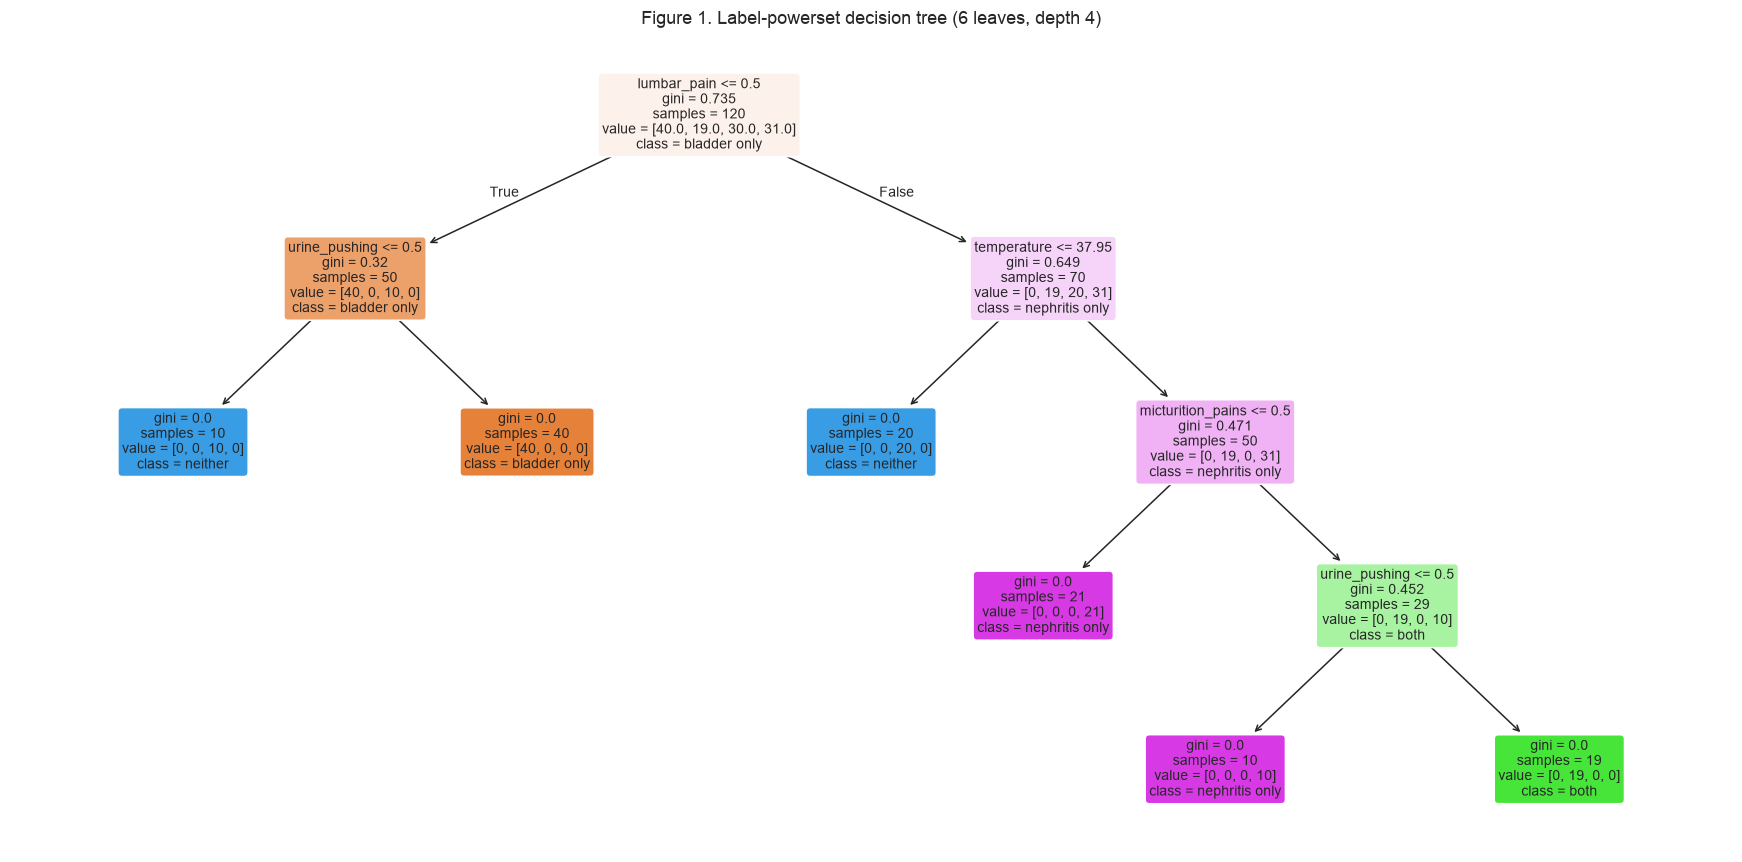

In [3]:
X_diag = diagnosis[SYMPTOM_COLUMNS]
y_joint = diagnosis["diagnosis"]
Y_binary = diagnosis[LABEL_COLUMNS]


def fit_tree(X, y):
    tree = DecisionTreeClassifier(random_state=RANDOM_STATE)
    tree.fit(X, y)
    return tree


def exact_match(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    if y_true.ndim == 1:
        return accuracy_score(y_true, y_pred)
    return float(np.mean(np.all(y_true == y_pred, axis=1)))


powerset_tree = fit_tree(X_diag, y_joint)
multioutput_tree = fit_tree(X_diag, Y_binary)
bladder_tree = fit_tree(X_diag, Y_binary["bladder"])
nephritis_tree = fit_tree(X_diag, Y_binary["nephritis"])
binary_relevance_pred = np.column_stack(
    [
        bladder_tree.predict(X_diag),
        nephritis_tree.predict(X_diag),
    ]
)

method_summary = pd.DataFrame(
    [
        {
            "method": "label powerset",
            "train_accuracy": exact_match(y_joint, powerset_tree.predict(X_diag)),
            "leaves": powerset_tree.get_n_leaves(),
            "depth": powerset_tree.get_depth(),
        },
        {
            "method": "multi-output tree",
            "train_accuracy": exact_match(Y_binary, multioutput_tree.predict(X_diag)),
            "leaves": multioutput_tree.get_n_leaves(),
            "depth": multioutput_tree.get_depth(),
        },
        {
            "method": "binary relevance",
            "train_accuracy": exact_match(Y_binary, binary_relevance_pred),
            "leaves": bladder_tree.get_n_leaves() + nephritis_tree.get_n_leaves(),
            "depth": max(bladder_tree.get_depth(), nephritis_tree.get_depth()),
        },
    ]
)
display(method_summary)

fig, ax = plt.subplots(figsize=(16, 8))
plot_tree(
    powerset_tree,
    feature_names=SYMPTOM_COLUMNS,
    class_names=list(powerset_tree.classes_),
    filled=True,
    rounded=True,
    fontsize=9,
    ax=ax,
)
ax.set_title(
    f"Figure 1. Label-powerset decision tree "
    f"({powerset_tree.get_n_leaves()} leaves, depth {powerset_tree.get_depth()})"
)
fig.tight_layout()
plt.show()


### (c) Convert the decision rules

Each root-to-leaf path of the label-powerset tree is one rule. Binary symptoms are stored as 0/1, and the tree splits them at 0.5, so those splits are written as `yes` or `no`. The extraction follows the traversal in the KDnuggets article cited at the end of the notebook: walk left when the feature is at most the threshold, walk right otherwise, and read the predicted class from the leaf.


In [4]:
def split_text(feature, threshold, go_left):
    if feature in BINARY_SYMPTOMS and 0 < threshold < 1:
        return f"{feature} = {'no' if go_left else 'yes'}"
    operator = "<=" if go_left else ">"
    return f"{feature} {operator} {threshold:.2f}"


def extract_rules(model, feature_names):
    tree = model.tree_
    rules = []

    def walk(node, conditions):
        if tree.feature[node] < 0:
            counts = tree.value[node][0]
            predicted = model.classes_[int(np.argmax(counts))]
            rules.append((conditions, predicted, int(tree.n_node_samples[node])))
            return
        feature = feature_names[tree.feature[node]]
        threshold = tree.threshold[node]
        walk(tree.children_left[node], conditions + [split_text(feature, threshold, True)])
        walk(tree.children_right[node], conditions + [split_text(feature, threshold, False)])

    walk(0, [])
    return rules


def print_rules(rules):
    for index, (conditions, predicted, n_samples) in enumerate(rules, start=1):
        condition_text = " AND ".join(conditions) if conditions else "TRUE"
        print(f"Rule {index}: IF {condition_text} THEN {predicted} (n={n_samples})")


full_rules = extract_rules(powerset_tree, SYMPTOM_COLUMNS)
print(f"{len(full_rules)} rules from the unpruned tree")
print_rules(full_rules)


6 rules from the unpruned tree
Rule 1: IF lumbar_pain = no AND urine_pushing = no THEN neither (n=10)
Rule 2: IF lumbar_pain = no AND urine_pushing = yes THEN bladder only (n=40)
Rule 3: IF lumbar_pain = yes AND temperature <= 37.95 THEN neither (n=20)
Rule 4: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = no THEN nephritis only (n=21)
Rule 5: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = no THEN nephritis only (n=10)
Rule 6: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = yes THEN both (n=19)


### (d) Cost-complexity pruning

Cost-complexity pruning scores a tree by training error plus `alpha` times the number of leaves. A larger `alpha` removes more leaves. `alpha` is chosen on the training rows by stratified 5-fold accuracy. Every class has at least 19 patients, so five folds are valid. The selected tree is the smallest one whose cross-validated accuracy matches the best accuracy on the path. That is the minimal tree that does not give up predictive accuracy, and its rules are the interpretable set requested in this part.


,ccp_alpha,cv_accuracy,cv_std,train_accuracy,n_leaves,depth
0,0.0000,0.9917,0.0186,1.0000,6,4
1,0.0982,0.8583,0.0559,0.8417,4,2
2,0.1333,0.7667,0.0697,0.7583,3,2
3,0.1820,0.6750,0.0745,0.5917,2,1
4,0.2229,0.4833,0.1369,0.3333,1,0


Selected ccp_alpha = 0; leaves = 6; CV accuracy = 0.9917


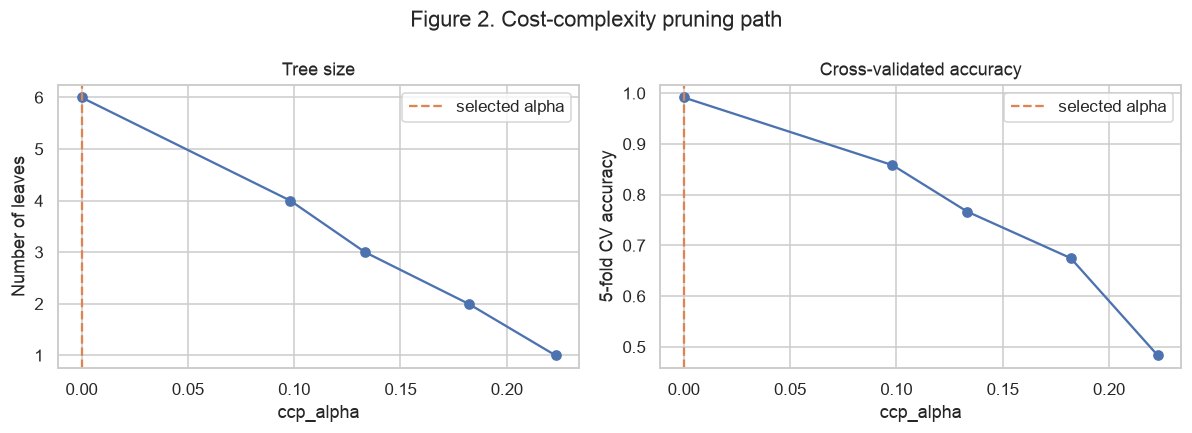

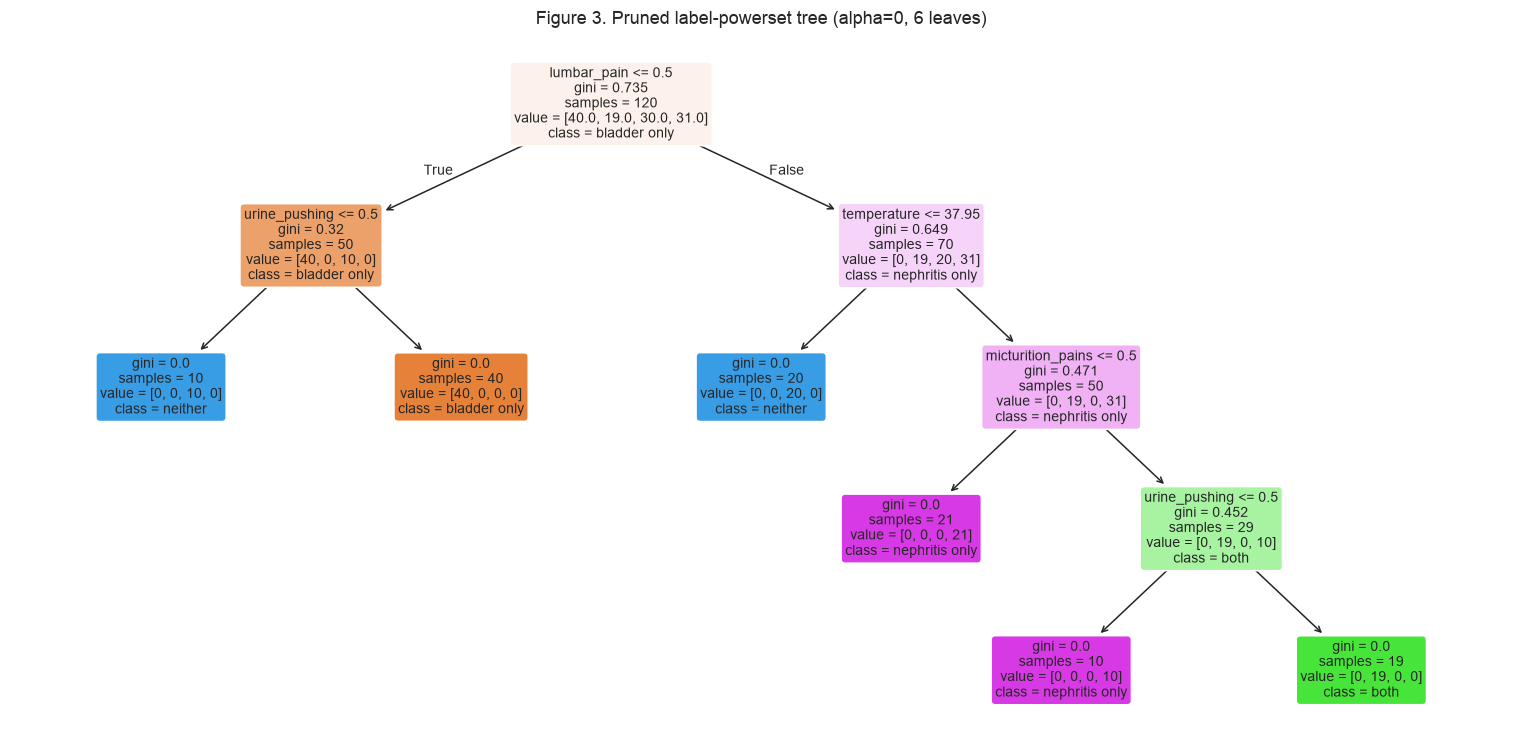

6 rules from the pruned tree
Rule 1: IF lumbar_pain = no AND urine_pushing = no THEN neither (n=10)
Rule 2: IF lumbar_pain = no AND urine_pushing = yes THEN bladder only (n=40)
Rule 3: IF lumbar_pain = yes AND temperature <= 37.95 THEN neither (n=20)
Rule 4: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = no THEN nephritis only (n=21)
Rule 5: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = no THEN nephritis only (n=10)
Rule 6: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = yes THEN both (n=19)


In [5]:
pruning_path = powerset_tree.cost_complexity_pruning_path(X_diag, y_joint)
candidate_alphas = np.unique(np.clip(pruning_path.ccp_alphas, 0, None))
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

pruning_rows = []
for alpha in candidate_alphas:
    candidate = DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=float(alpha))
    scores = cross_val_score(candidate, X_diag, y_joint, cv=cv, scoring="accuracy")
    candidate.fit(X_diag, y_joint)
    pruning_rows.append(
        {
            "ccp_alpha": float(alpha),
            "cv_accuracy": float(scores.mean()),
            "cv_std": float(scores.std(ddof=1)),
            "train_accuracy": exact_match(y_joint, candidate.predict(X_diag)),
            "n_leaves": candidate.get_n_leaves(),
            "depth": candidate.get_depth(),
        }
    )

pruning_df = pd.DataFrame(pruning_rows)
best_cv = pruning_df["cv_accuracy"].max()
tied = pruning_df[np.isclose(pruning_df["cv_accuracy"], best_cv)]
selected = tied.sort_values(["n_leaves", "ccp_alpha"], ascending=[True, False]).iloc[0]
selected_alpha = float(selected["ccp_alpha"])

display(pruning_df)
print(
    f"Selected ccp_alpha = {selected_alpha:.6g}; "
    f"leaves = {int(selected['n_leaves'])}; "
    f"CV accuracy = {selected['cv_accuracy']:.4f}"
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(pruning_df["ccp_alpha"], pruning_df["n_leaves"], marker="o")
axes[0].axvline(selected_alpha, color="C1", linestyle="--", label="selected alpha")
axes[0].set_xlabel("ccp_alpha")
axes[0].set_ylabel("Number of leaves")
axes[0].set_title("Tree size")
axes[0].legend()
axes[1].plot(pruning_df["ccp_alpha"], pruning_df["cv_accuracy"], marker="o")
axes[1].axvline(selected_alpha, color="C1", linestyle="--", label="selected alpha")
axes[1].set_xlabel("ccp_alpha")
axes[1].set_ylabel("5-fold CV accuracy")
axes[1].set_title("Cross-validated accuracy")
axes[1].legend()
fig.suptitle("Figure 2. Cost-complexity pruning path")
fig.tight_layout()
plt.show()

pruned_tree = DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=selected_alpha)
pruned_tree.fit(X_diag, y_joint)
pruned_rules = extract_rules(pruned_tree, SYMPTOM_COLUMNS)

fig, ax = plt.subplots(figsize=(14, 7))
plot_tree(
    pruned_tree,
    feature_names=SYMPTOM_COLUMNS,
    class_names=list(pruned_tree.classes_),
    filled=True,
    rounded=True,
    fontsize=9,
    ax=ax,
)
ax.set_title(
    f"Figure 3. Pruned label-powerset tree "
    f"(alpha={selected_alpha:.4g}, {pruned_tree.get_n_leaves()} leaves)"
)
fig.tight_layout()
plt.show()

print(f"{len(pruned_rules)} rules from the pruned tree")
print_rules(pruned_rules)


The path selects `ccp_alpha = 0`. That tree has 6 leaves, training accuracy 1, and 5-fold accuracy 0.9917. The next value, `alpha = 0.098`, drops cross-validated accuracy to 0.8583. The fold-score standard deviation at the best tree is 0.0186, so one standard error of the mean is about 0.008. The smaller trees fall well outside that band, and the one-standard-error rule keeps the same 6-leaf tree.

The unpruned tree is already the minimal tree with high accuracy. Its six rules are the interpretable set: bladder inflammation is the branch with urine pushing and no lumbar pain, and nephritis is the branch with lumbar pain and temperature above 37.95. The two diagnoses occur together only when those nephritis conditions are joined by urine pushing and micturition pains.


## 2. The LASSO and Boosting for Regression

The response is `ViolentCrimesPerPop`. Test error in parts (f) through (j) is the mean squared error on the held-out communities. The row split is fixed by the assignment. The imputer, the penalty parameters, the number of principal components, and the boosting penalty are all chosen from the training rows only.


### (a) Obtain Data

`communities.data` has 1,994 communities and 128 comma-separated attributes. Missing entries are stored as `?`. The description lists five non-predictive attributes (`state`, `county`, `community`, `communityname`, `fold`), 122 predictive attributes, and one goal attribute. The first 1,495 rows are the training set and the remaining 499 rows are the test set.


In [6]:
CRIME_COLUMNS = [
    "state", "county", "community", "communityname", "fold",
    "population", "householdsize", "racepctblack", "racePctWhite", "racePctAsian",
    "racePctHisp", "agePct12t21", "agePct12t29", "agePct16t24", "agePct65up",
    "numbUrban", "pctUrban", "medIncome", "pctWWage", "pctWFarmSelf",
    "pctWInvInc", "pctWSocSec", "pctWPubAsst", "pctWRetire", "medFamInc",
    "perCapInc", "whitePerCap", "blackPerCap", "indianPerCap", "AsianPerCap",
    "OtherPerCap", "HispPerCap", "NumUnderPov", "PctPopUnderPov", "PctLess9thGrade",
    "PctNotHSGrad", "PctBSorMore", "PctUnemployed", "PctEmploy", "PctEmplManu",
    "PctEmplProfServ", "PctOccupManu", "PctOccupMgmtProf", "MalePctDivorce",
    "MalePctNevMarr", "FemalePctDiv", "TotalPctDiv", "PersPerFam", "PctFam2Par",
    "PctKids2Par", "PctYoungKids2Par", "PctTeen2Par", "PctWorkMomYoungKids",
    "PctWorkMom", "NumIlleg", "PctIlleg", "NumImmig", "PctImmigRecent",
    "PctImmigRec5", "PctImmigRec8", "PctImmigRec10", "PctRecentImmig", "PctRecImmig5",
    "PctRecImmig8", "PctRecImmig10", "PctSpeakEnglOnly", "PctNotSpeakEnglWell",
    "PctLargHouseFam", "PctLargHouseOccup", "PersPerOccupHous", "PersPerOwnOccHous",
    "PersPerRentOccHous", "PctPersOwnOccup", "PctPersDenseHous", "PctHousLess3BR",
    "MedNumBR", "HousVacant", "PctHousOccup", "PctHousOwnOcc", "PctVacantBoarded",
    "PctVacMore6Mos", "MedYrHousBuilt", "PctHousNoPhone", "PctWOFullPlumb",
    "OwnOccLowQuart", "OwnOccMedVal", "OwnOccHiQuart", "RentLowQ", "RentMedian",
    "RentHighQ", "MedRent", "MedRentPctHousInc", "MedOwnCostPctInc",
    "MedOwnCostPctIncNoMtg", "NumInShelters", "NumStreet", "PctForeignBorn",
    "PctBornSameState", "PctSameHouse85", "PctSameCity85", "PctSameState85",
    "LemasSwornFT", "LemasSwFTPerPop", "LemasSwFTFieldOps", "LemasSwFTFieldPerPop",
    "LemasTotalReq", "LemasTotReqPerPop", "PolicReqPerOffic", "PolicPerPop",
    "RacialMatchCommPol", "PctPolicWhite", "PctPolicBlack", "PctPolicHisp",
    "PctPolicAsian", "PctPolicMinor", "OfficAssgnDrugUnits", "NumKindsDrugsSeiz",
    "PolicAveOTWorked", "LandArea", "PopDens", "PctUsePubTrans", "PolicCars",
    "PolicOperBudg", "LemasPctPolicOnPatr", "LemasGangUnitDeploy",
    "LemasPctOfficDrugUn", "PolicBudgPerPop", "ViolentCrimesPerPop",
]
NON_PREDICTIVE = ["state", "county", "community", "communityname", "fold"]
TARGET = "ViolentCrimesPerPop"

crime = pd.read_csv(
    DATA_DIR / "communities.data",
    header=None,
    names=CRIME_COLUMNS,
    na_values="?",
)
assert crime.shape == (1994, 128)

crime_model = crime.drop(columns=NON_PREDICTIVE)
feature_names = [column for column in crime_model.columns if column != TARGET]
train_raw = crime_model.iloc[:N_TRAIN].copy()
test_raw = crime_model.iloc[N_TRAIN:].copy()

print(f"All rows: {len(crime)}")
print(f"Training rows: {len(train_raw)}")
print(f"Test rows: {len(test_raw)}")
print(f"Predictive features: {len(feature_names)}")
print(f"Non-predictive features removed: {NON_PREDICTIVE}")


All rows: 1994
Training rows: 1495
Test rows: 499
Predictive features: 122
Non-predictive features removed: ['state', 'county', 'community', 'communityname', 'fold']


### (b) Missing values

The non-predictive columns are already removed. Most missing entries are in the LEMAS police-department attributes, which were collected only for a subset of departments, so those rows cannot be dropped. Missing predictive values are replaced by the training-set mean of that feature. The same training means are applied to the test set. The response has no missing values.


In [7]:
missing_counts = train_raw[feature_names].isna().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)
print(f"Training features with missing values: {len(missing_counts)}")
print(f"Training missing entries: {int(train_raw[feature_names].isna().sum().sum())}")
print(f"Test missing entries: {int(test_raw[feature_names].isna().sum().sum())}")
display(missing_counts.rename("training_missing").to_frame())

imputer = SimpleImputer(strategy="mean")
X_train = pd.DataFrame(
    imputer.fit_transform(train_raw[feature_names]),
    columns=feature_names,
    index=train_raw.index,
)
X_test = pd.DataFrame(
    imputer.transform(test_raw[feature_names]),
    columns=feature_names,
    index=test_raw.index,
)
y_train = train_raw[TARGET].to_numpy()
y_test = test_raw[TARGET].to_numpy()

print(f"Missing values after imputation: {int(X_train.isna().sum().sum() + X_test.isna().sum().sum())}")


Training features with missing values: 23
Training missing entries: 27633
Test missing entries: 9218


,training_missing
PctPolicBlack,1256
PctPolicHisp,1256
LemasGangUnitDeploy,1256
LemasPctPolicOnPatr,1256
PolicOperBudg,1256
PolicCars,1256
PolicAveOTWorked,1256
NumKindsDrugsSeiz,1256
OfficAssgnDrugUnits,1256
PctPolicMinor,1256


Missing values after imputation: 0


### (c) Plot a correlation matrix

The matrix is the Pearson correlation of the 122 imputed predictive features on the training set. The response is not included. Tick labels are small because there are 122 names; the color scale is the quantity the figure is meant to show. Large blocks of the same color are groups of census attributes that move together, such as income, education, and family structure.


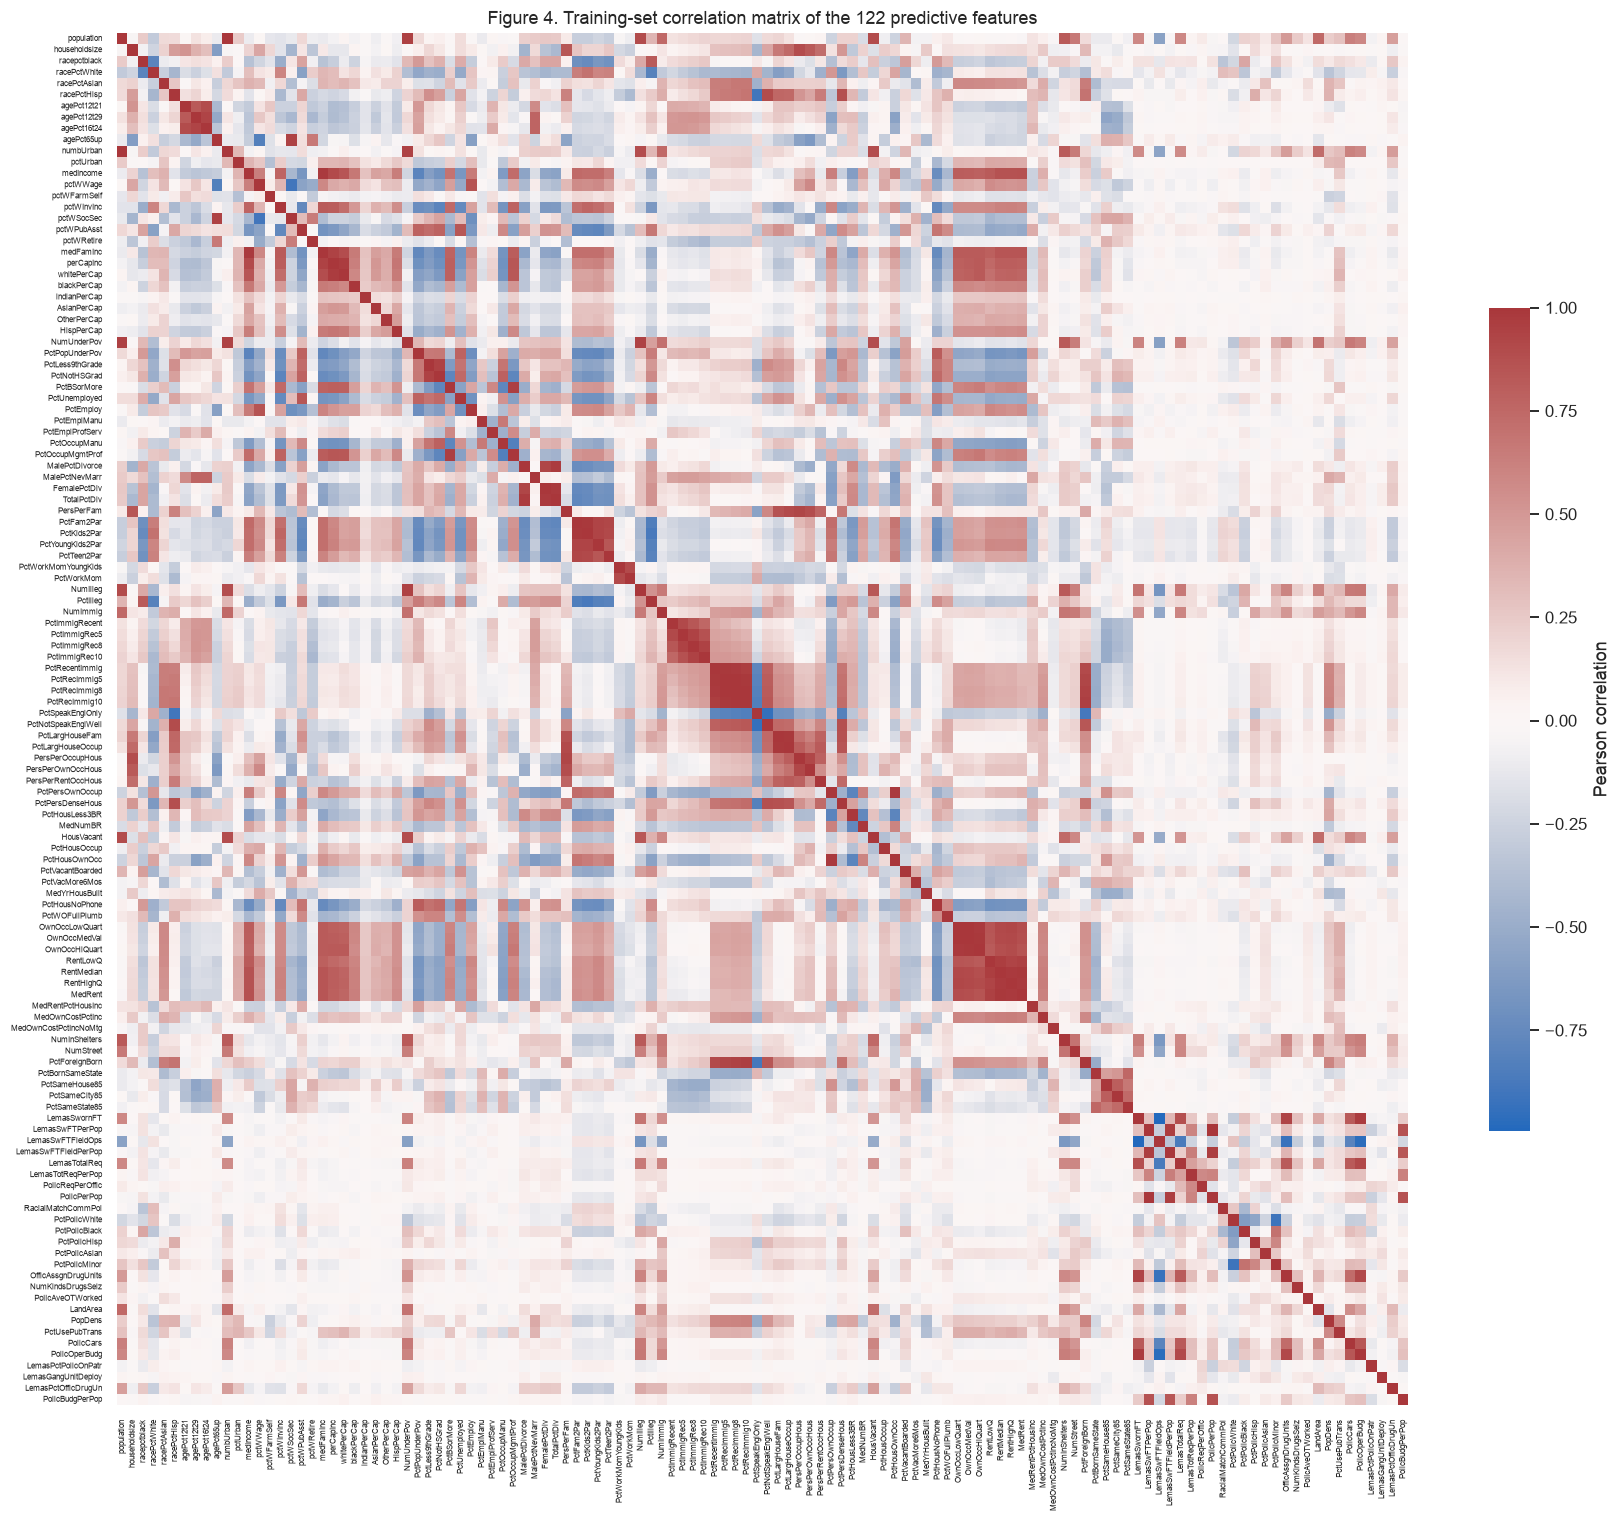

In [8]:
correlation = X_train.corr()
fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(
    correlation,
    cmap="vlag",
    center=0,
    xticklabels=True,
    yticklabels=True,
    cbar_kws={"shrink": 0.6, "label": "Pearson correlation"},
    ax=ax,
)
ax.tick_params(axis="both", labelsize=5)
ax.set_title("Figure 4. Training-set correlation matrix of the 122 predictive features")
fig.tight_layout()
plt.show()


### (d) Calculate the Coefficient of Variation CV

For each training feature, CV is the sample standard deviation divided by the sample mean. The features have already been normalized to [0, 1], so a large CV usually means the mass of the feature sits near 0 while a few communities take much larger values.


In [9]:
cv_table = pd.DataFrame(
    {
        "mean": X_train.mean(),
        "std": X_train.std(ddof=1),
    }
)
cv_table["CV"] = cv_table["std"] / cv_table["mean"]
cv_table = cv_table.sort_values("CV", ascending=False)
print(f"Features with a zero mean: {int((cv_table['mean'] == 0).sum())}")
display(cv_table)


Features with a zero mean: 0


,mean,std,CV
NumStreet,0.0230,0.0987,4.2929
NumInShelters,0.0296,0.1027,3.4710
NumIlleg,0.0372,0.1138,3.0590
NumImmig,0.0306,0.0895,2.9266
LemasPctOfficDrugUn,0.0933,0.2382,2.5529
NumUnderPov,0.0568,0.1332,2.3424
population,0.0582,0.1304,2.2411
numbUrban,0.0646,0.1318,2.0385
HousVacant,0.0765,0.1505,1.9685
LandArea,0.0641,0.1055,1.6454


### (e) Scatter plots and box plots for highest CV features

The assignment asks for the features with the highest CV, and the count is the floor of the square root of 128. That is 11, using the original attribute count of 128 rather than the 122 predictive features that remain after the non-predictive columns are removed. The scatter plots use the training response. The boxplots show the marginal distribution of each selected feature.


floor(sqrt(128)) = 11


,mean,std,CV
NumStreet,0.0230,0.0987,4.2929
NumInShelters,0.0296,0.1027,3.4710
NumIlleg,0.0372,0.1138,3.0590
NumImmig,0.0306,0.0895,2.9266
LemasPctOfficDrugUn,0.0933,0.2382,2.5529
NumUnderPov,0.0568,0.1332,2.3424
population,0.0582,0.1304,2.2411
numbUrban,0.0646,0.1318,2.0385
HousVacant,0.0765,0.1505,1.9685
LandArea,0.0641,0.1055,1.6454


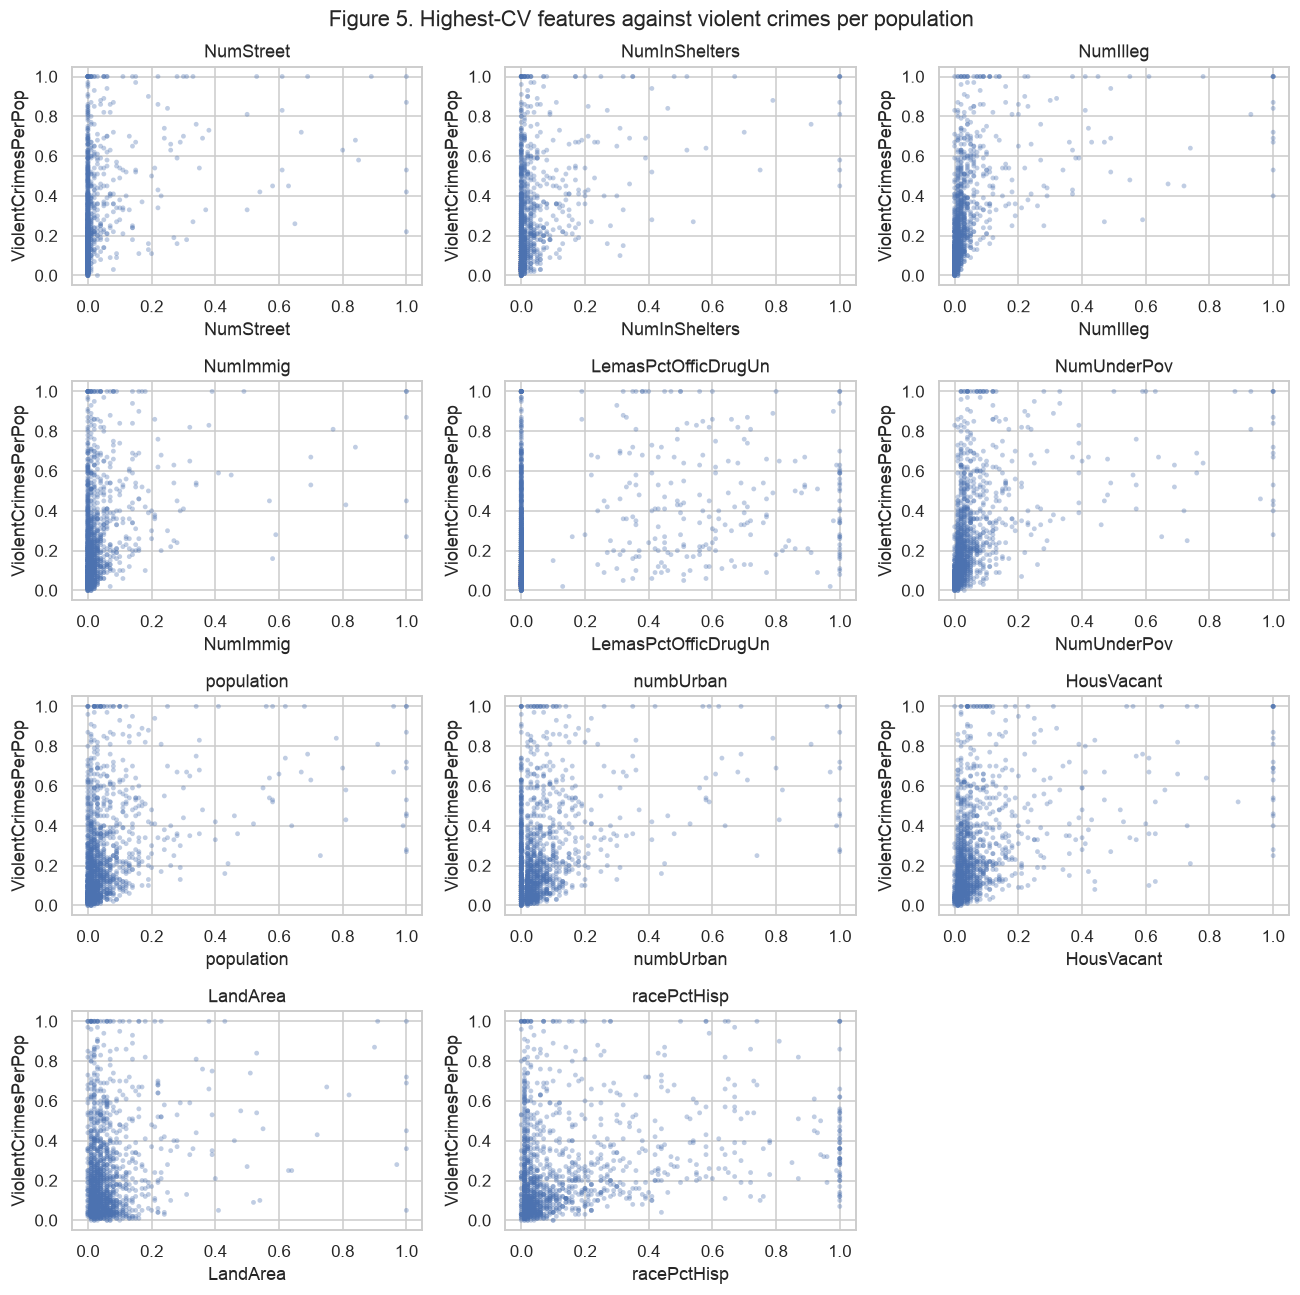

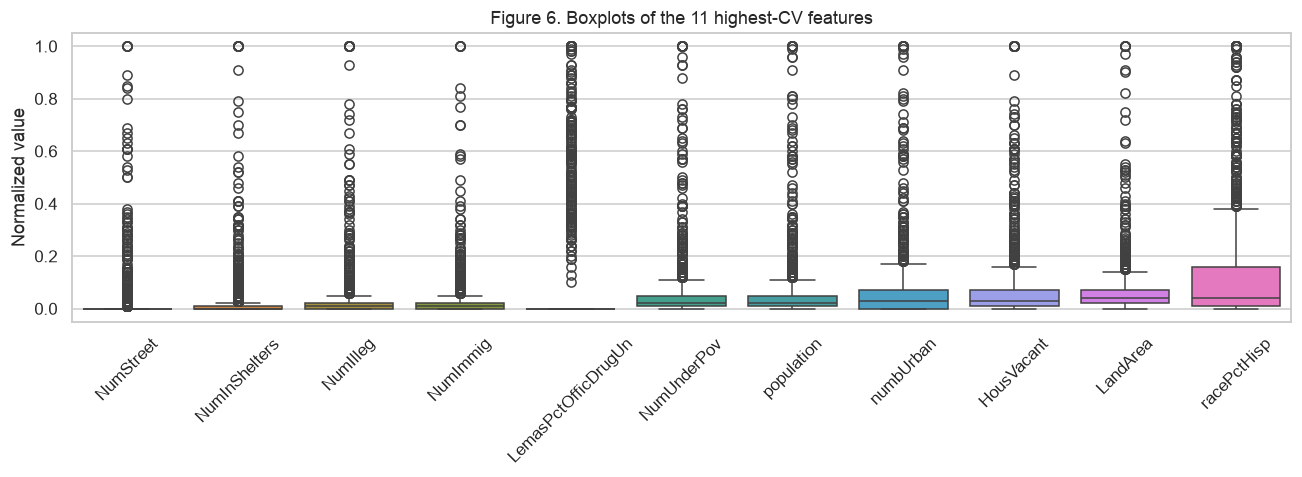

In [10]:
n_high_cv = int(np.floor(np.sqrt(128)))
high_cv_features = cv_table.head(n_high_cv).index.tolist()
print(f"floor(sqrt(128)) = {n_high_cv}")
display(cv_table.loc[high_cv_features])

fig, axes = plt.subplots(4, 3, figsize=(12, 12))
for axis, feature in zip(axes.ravel(), high_cv_features):
    axis.scatter(X_train[feature], y_train, s=10, alpha=0.35, edgecolors="none")
    axis.set_xlabel(feature)
    axis.set_ylabel("ViolentCrimesPerPop")
    axis.set_title(feature)
axes.ravel()[-1].axis("off")
fig.suptitle("Figure 5. Highest-CV features against violent crimes per population")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 4.5))
sns.boxplot(data=X_train[high_cv_features], ax=ax)
ax.tick_params(axis="x", rotation=45)
ax.set_ylabel("Normalized value")
ax.set_title("Figure 6. Boxplots of the 11 highest-CV features")
fig.tight_layout()
plt.show()


No. These plots do not support a conclusion about statistical significance.

The 11 features are `NumStreet`, `NumInShelters`, `NumIlleg`, `NumImmig`, `LemasPctOfficDrugUn`, `NumUnderPov`, `population`, `numbUrban`, `HousVacant`, `LandArea`, and `racePctHisp`. Most are counts. After normalization their mass sits near 0, which is why the coefficient of variation is large and why the boxplots are long right tails. A high CV is a statement about that shape, not about the crime rate.

A scatter plot can suggest a slope, but it does not supply a standard error, and it cannot separate one feature from the others it moves with. Significance would require a model and a test. The plots describe spread and a rough association only.


### (f) Fit a linear model

Ordinary least squares is fit to the 122 imputed training features. The reported test error is the MSE on the 499 test communities.


In [11]:
def regression_mse(model, X_tr, y_tr, X_te, y_te):
    fitted = clone(model).fit(X_tr, y_tr)
    train_error = mean_squared_error(y_tr, fitted.predict(X_tr))
    test_error = mean_squared_error(y_te, fitted.predict(X_te))
    return fitted, train_error, test_error


ols, ols_train_mse, ols_test_mse = regression_mse(
    LinearRegression(), X_train, y_train, X_test, y_test
)
print(f"OLS training MSE: {ols_train_mse:.6f}")
print(f"OLS test MSE: {ols_test_mse:.6f}")


OLS training MSE: 0.016309
OLS test MSE: 0.018142


### (g) Fit a ridge regression model

The ridge penalty `lambda` is chosen by 5-fold cross-validation on the training set. The features are left on their given [0, 1] scale. Part (h) is the part that repeats a penalized model after standardization.


In [12]:
RIDGE_ALPHAS = np.logspace(-3, 3, 50)
ridge, ridge_train_mse, ridge_test_mse = regression_mse(
    RidgeCV(alphas=RIDGE_ALPHAS, cv=CV_FOLDS),
    X_train,
    y_train,
    X_test,
    y_test,
)
print(f"Ridge lambda chosen by CV: {ridge.alpha_:.6g}")
print(f"Ridge training MSE: {ridge_train_mse:.6f}")
print(f"Ridge test MSE: {ridge_test_mse:.6f}")


Ridge lambda chosen by CV: 2.02359
Ridge training MSE: 0.016936
Ridge test MSE: 0.017620


### (h) Fit a LASSO model

`lambda` is chosen by 5-fold `LassoCV` on the training set. A feature is selected when its coefficient is not zero. The fit is then repeated after standardizing the predictors with a `StandardScaler` fit on the training set only. The footnote is right that these attributes are already normalized to [0, 1]. Standardization is a second step: it gives every feature unit sample variance, so the L1 penalty charges coefficients on a common scale. Normalization into a shared range does not do that, because a skewed count and a percentage can both lie in [0, 1] and still have very different variances.


In [13]:
def selected_coefficients(model, names):
    coefficients = pd.Series(model.coef_, index=names)
    selected = coefficients[coefficients != 0].sort_values(key=np.abs, ascending=False)
    return selected.rename("coefficient").to_frame()


lasso, lasso_train_mse, lasso_test_mse = regression_mse(
    LassoCV(cv=CV_FOLDS, random_state=RANDOM_STATE, max_iter=20000),
    X_train,
    y_train,
    X_test,
    y_test,
)
lasso_selected = selected_coefficients(lasso, feature_names)
print(f"LASSO lambda chosen by CV: {lasso.alpha_:.6g}")
print(f"LASSO training MSE: {lasso_train_mse:.6f}")
print(f"LASSO test MSE: {lasso_test_mse:.6f}")
print(f"Variables selected: {len(lasso_selected)}")
display(lasso_selected)

scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)
lasso_std, lasso_std_train_mse, lasso_std_test_mse = regression_mse(
    LassoCV(cv=CV_FOLDS, random_state=RANDOM_STATE, max_iter=20000),
    X_train_std,
    y_train,
    X_test_std,
    y_test,
)
lasso_std_selected = selected_coefficients(lasso_std, feature_names)
print(f"Standardized LASSO lambda chosen by CV: {lasso_std.alpha_:.6g}")
print(f"Standardized LASSO training MSE: {lasso_std_train_mse:.6f}")
print(f"Standardized LASSO test MSE: {lasso_std_test_mse:.6f}")
print(f"Variables selected after standardization: {len(lasso_std_selected)}")
display(lasso_std_selected)

print(
    "Test MSE, original scale: "
    f"{lasso_test_mse:.6f}; after standardization: {lasso_std_test_mse:.6f}."
)


LASSO lambda chosen by CV: 0.000116147
LASSO training MSE: 0.016977
LASSO test MSE: 0.017758
Variables selected: 75


,coefficient
racepctblack,0.2720
agePct12t29,-0.2654
PctPersDenseHous,0.2190
PctKids2Par,-0.1966
NumStreet,0.1664
MedRent,0.1612
RentLowQ,-0.1589
PctPopUnderPov,-0.1412
PctEmploy,0.1374
MalePctNevMarr,0.1332


Standardized LASSO lambda chosen by CV: 0.000763083
Standardized LASSO training MSE: 0.017044
Standardized LASSO test MSE: 0.017805
Variables selected after standardization: 73


,coefficient
racepctblack,0.0682
PctPersDenseHous,0.0406
PctKids2Par,-0.0398
agePct12t29,-0.0383
RentLowQ,-0.0277
PctPopUnderPov,-0.0267
MedRent,0.0264
PctIlleg,0.0247
PctWorkMom,-0.0214
PctEmploy,0.0212


Test MSE, original scale: 0.017758; after standardization: 0.017805.


On the original scale the test MSE is 0.017758 and 75 variables have nonzero coefficients. After standardization the test MSE is 0.017805 and 73 variables are selected. The test errors differ by about 0.00005. The raw attributes already share the range [0, 1], so giving them unit variance does not rebuild the regression. It does change the penalty: on the original scale a feature with small variance is charged more for the same coefficient, and standardization moves that weight. The two selected sets are mostly the same features, with coefficients now measured per standard deviation rather than per unit of the normalized attribute.


### (i) Fit a PCR model

Principal component regression keeps the first `M` principal components of the training features and then fits least squares. `M` is chosen by 5-fold CV. Inside each fold the components are recomputed on that fold's training rows, so the validation rows do not enter the decomposition. The attributes are already normalized to [0, 1], and this part does not standardize them again. The selected `M` is refit on the full training set before the test MSE is computed.


M chosen by CV: 96
CV MSE at that M: 0.019342
PCR training MSE: 0.016606
PCR test MSE: 0.018472
Variance explained by the retained components: 0.9989


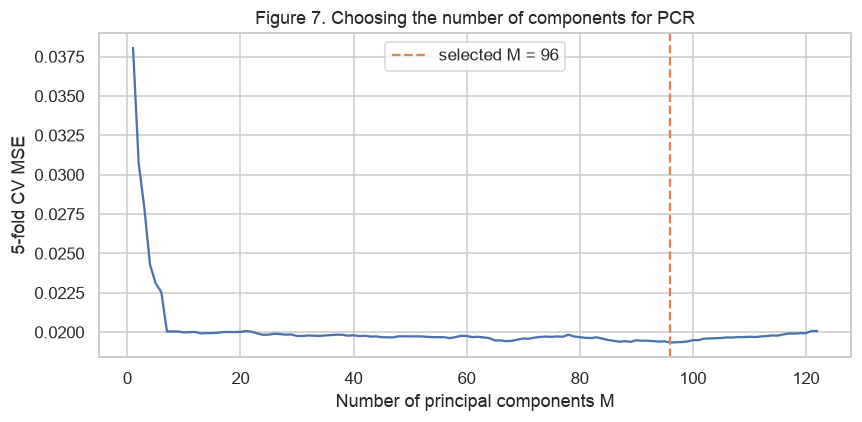

In [14]:
def pcr_cv_curve(X, y, n_splits=CV_FOLDS):
    X = np.asarray(X)
    y = np.asarray(y)
    n_features = X.shape[1]
    fold_mse = np.empty((n_splits, n_features))
    splitter = KFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    for fold_id, (train_index, valid_index) in enumerate(splitter.split(X)):
        pca = PCA().fit(X[train_index])
        train_scores = pca.transform(X[train_index])
        valid_scores = pca.transform(X[valid_index])
        for n_components in range(1, n_features + 1):
            model = LinearRegression().fit(train_scores[:, :n_components], y[train_index])
            prediction = model.predict(valid_scores[:, :n_components])
            fold_mse[fold_id, n_components - 1] = mean_squared_error(y[valid_index], prediction)
    return fold_mse.mean(axis=0)


pcr_cv_mse = pcr_cv_curve(X_train, y_train)
best_m = int(np.argmin(pcr_cv_mse) + 1)
pcr = PCA(n_components=best_m).fit(X_train)
pcr_ols = LinearRegression().fit(pcr.transform(X_train), y_train)
pcr_train_mse = mean_squared_error(y_train, pcr_ols.predict(pcr.transform(X_train)))
pcr_test_mse = mean_squared_error(y_test, pcr_ols.predict(pcr.transform(X_test)))

print(f"M chosen by CV: {best_m}")
print(f"CV MSE at that M: {pcr_cv_mse[best_m - 1]:.6f}")
print(f"PCR training MSE: {pcr_train_mse:.6f}")
print(f"PCR test MSE: {pcr_test_mse:.6f}")
print(f"Variance explained by the retained components: {pcr.explained_variance_ratio_.sum():.4f}")

fig, ax = plt.subplots(figsize=(8, 4))
component_grid = np.arange(1, len(pcr_cv_mse) + 1)
ax.plot(component_grid, pcr_cv_mse)
ax.axvline(best_m, color="C1", linestyle="--", label=f"selected M = {best_m}")
ax.set_xlabel("Number of principal components M")
ax.set_ylabel("5-fold CV MSE")
ax.set_title("Figure 7. Choosing the number of components for PCR")
ax.legend()
fig.tight_layout()
plt.show()


Cross-validation keeps `M = 96` components. Those components explain 0.9989 of the training-feature variance, so the fit is close to least squares on all 122 features. The test MSE is 0.018472, slightly above the OLS test MSE of 0.018142. With this many components, PCR is not buying a simpler model than the linear fit in part (f).


### (j) Fit a boosting tree

XGBoost is used as the L1-penalized gradient boosting tree. Its `reg_alpha` parameter is the L1 penalty on the leaf weights, which is the regularization term `alpha` in this part. `alpha` is chosen by 5-fold CV on the training set. The search grid is nine values on a log scale from 0.001 to 10. The other boosting settings are held fixed: 200 trees, depth 3, learning rate 0.08, and the default L2 leaf penalty. The test MSE is reported with the selected `alpha` so this fit can be compared with parts (f) through (i).


In [15]:
boosting = XGBRegressor(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.08,
    reg_lambda=1.0,
    objective="reg:squarederror",
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=4,
    verbosity=0,
)
boosting_search = GridSearchCV(
    boosting,
    param_grid={"reg_alpha": np.logspace(-3, 1, 9)},
    scoring="neg_mean_squared_error",
    cv=CV_FOLDS,
    n_jobs=1,
)
boosting_search.fit(X_train, y_train)
best_alpha = float(boosting_search.best_params_["reg_alpha"])
boosting_train_mse = mean_squared_error(y_train, boosting_search.predict(X_train))
boosting_test_mse = mean_squared_error(y_test, boosting_search.predict(X_test))

alpha_path = pd.DataFrame(boosting_search.cv_results_)
alpha_path = alpha_path[["param_reg_alpha", "mean_test_score", "std_test_score"]].copy()
alpha_path["cv_mse"] = -alpha_path["mean_test_score"]
alpha_path = alpha_path.rename(columns={"param_reg_alpha": "alpha"})
display(alpha_path[["alpha", "cv_mse", "std_test_score"]])

print(f"alpha chosen by CV: {best_alpha:.6g}")
print(f"Boosting training MSE: {boosting_train_mse:.6f}")
print(f"Boosting test MSE: {boosting_test_mse:.6f}")

test_error_summary = pd.DataFrame(
    [
        ("OLS", ols_test_mse),
        ("Ridge", ridge_test_mse),
        ("LASSO", lasso_test_mse),
        ("LASSO, standardized features", lasso_std_test_mse),
        ("PCR", pcr_test_mse),
        ("L1 gradient boosting", boosting_test_mse),
    ],
    columns=["model", "test_mse"],
)
display(test_error_summary)


,alpha,cv_mse,std_test_score
0,0.0010,0.0205,0.0026
1,0.0032,0.0206,0.0026
2,0.0100,0.0208,0.0027
3,0.0316,0.0206,0.0026
4,0.1000,0.0207,0.0031
5,0.3162,0.0201,0.0033
6,1.0000,0.0205,0.0036
7,3.1623,0.0203,0.0034
8,10.0000,0.0217,0.0031


alpha chosen by CV: 0.316228
Boosting training MSE: 0.006063
Boosting test MSE: 0.016311


,model,test_mse
0,OLS,0.0181
1,Ridge,0.0176
2,LASSO,0.0178
3,"LASSO, standardized features",0.0178
4,PCR,0.0185
5,L1 gradient boosting,0.0163


The cross-validation selects `alpha = 0.316`. The test MSE is 0.016311. That is the lowest test error of the six fits: OLS 0.018142, ridge 0.017620, LASSO 0.017758, standardized LASSO 0.017805, and PCR 0.018472. The training MSE, 0.006063, is lower than the test MSE, so the boosted trees fit the training communities more tightly than the linear models do, and the held-out error is still the best of the group.
